# Aula 01 - Introdução ao PLN e Pré-processamento

**Curso:** Processamento de Linguagem Natural  
**Aluno:** Brener Gomes dos Santos  
**Data:** 12/01/2026

## Instruções
1. Complete todos os exercícios marcados com `# === SEU CÓDIGO AQUI ===`
2. Execute as células de teste para verificar suas respostas
3. **Não modifique as células de teste**
4.  Execute todas as células em ordem
5.  Respostas devem ser armazenadas nas variáveis indicadas

## Critérios de Avaliação
- **Conteúdo (100%):** Testes automáticos

---

## Dataset

Utilizaremos o dataset **B2W-Reviews01**:
- Reviews de produtos de e-commerce brasileiro
- Texto em português brasileiro


## Setup

In [ ]:
# === CONFIGURAÇÃO INICIAL ===

!pip install --upgrade pip --quiet
!pip cache purge
!pip install otter-grader --no-cache-dir -q
!pip install nltk wordcloud --quiet
!mkdir -p tests

print("Ambiente configurado!")

Files removed: 2 (38 kB)
Ambiente configurado!


In [ ]:
%%writefile tests/q1.py
OK_FORMAT = True

test = {
    "name": "q1",
    "points": 10,
    "suites": [
        {
            "cases": [
                {
                    "code": r"""
                    >>> # Verificar se funcao existe
                    >>> assert callable(limpar_texto_regex), "Função limpar_texto_regex não foi definida"
                    """,
                    "hidden": False,
                    "locked": False
                },
                {
                    "code": r"""
                    >>> # Testar remoção de URLs
                    >>> resultado = limpar_texto_regex("Visite www.exemplo.com agora")
                    >>> assert "www" not in resultado, "URLs devem ser removidas"
                    """,
                    "hidden": False,
                    "locked": False
                },
                {
                    "code": r"""
                    >>> # Testar remoção de emails
                    >>> resultado = limpar_texto_regex("Contato: teste@email.com")
                    >>> assert "@" not in resultado, "Emails devem ser removidos"
                    """,
                    "hidden": False,
                    "locked": False
                },
                {
                    "code": r"""
                    >>> # Testar remoção de números
                    >>> resultado = limpar_texto_regex("Custou R$199 reais")
                    >>> assert not any(c.isdigit() for c in resultado), "Números devem ser removidos"
                    """,
                    "hidden": False,
                    "locked": False
                },
                {
                    "code": r"""
                    >>> # Testar lowercase
                    >>> resultado = limpar_texto_regex("TEXTO EM MAIÚSCULO")
                    >>> assert resultado == resultado.lower(), "Texto deve estar em minúsculas"
                    """,
                    "hidden": False,
                    "locked": False
                }
            ],
            "scored": True,
            "setup": "",
            "teardown": "",
            "type": "doctest"
        }
    ]
}

Overwriting tests/q1.py


In [ ]:
%%writefile tests/q2.py
OK_FORMAT = True

test = {
    "name": "q2",
    "points": 10,
    "suites": [
        {
            "cases": [
                {
                    "code": r"""
                    >>> # Verificar se variaveis existem
                    >>> assert 'tokens_review' in dir(), "Variável tokens_review não foi criada"
                    >>> assert 'sentencas_review' in dir(), "Variável sentencas_review não foi criada"
                    """,
                    "hidden": False,
                    "locked": False
                },
                {
                    "code": r"""
                    >>> # Verificar tipos
                    >>> assert isinstance(tokens_review, list), "tokens_review deve ser uma lista"
                    >>> assert isinstance(sentencas_review, list), "sentencas_review deve ser uma lista"
                    """,
                    "hidden": False,
                    "locked": False
                },
                {
                    "code": r"""
                    >>> # Verificar conteudo
                    >>> assert len(tokens_review) > 5, "tokens_review deve ter mais de 5 tokens"
                    >>> assert len(sentencas_review) >= 1, "sentencas_review deve ter pelo menos 1 sentença"
                    """,
                    "hidden": False,
                    "locked": False
                }
            ],
            "scored": True,
            "setup": "",
            "teardown": "",
            "type": "doctest"
        }
    ]
}

Overwriting tests/q2.py


In [ ]:
%%writefile tests/q3.py
OK_FORMAT = True

test = {
    "name": "q3",
    "points": 10,
    "suites": [
        {
            "cases": [
                {
                    "code": r"""
                    >>> # Verificar se variaveis existem
                    >>> assert 'tokens_sem_stopwords' in dir(), "Variável tokens_sem_stopwords não foi criada"
                    """,
                    "hidden": False,
                    "locked": False
                },
                {
                    "code": r"""
                    >>> # Verificar tipo
                    >>> assert isinstance(tokens_sem_stopwords, list), "tokens_sem_stopwords deve ser uma lista"
                    """,
                    "hidden": False,
                    "locked": False
                },
                {
                    "code": r"""
                    >>> # Verificar remoção de stopwords comuns
                    >>> stopwords_comuns = ['o', 'a', 'de', 'que', 'e', 'do', 'da', 'em', 'um', 'para']
                    >>> tokens_lower = [t.lower() for t in tokens_sem_stopwords]
                    >>> assert not any(sw in tokens_lower for sw in stopwords_comuns), "Stopwords não foram removidas corretamente"
                    """,
                    "hidden": False,
                    "locked": False
                },
                {
                    "code": r"""
                    >>> # Verificar que tokens válidos permanecem
                    >>> assert len(tokens_sem_stopwords) > 0, "Lista não deve estar vazia"
                    """,
                    "hidden": False,
                    "locked": False
                }
            ],
            "scored": True,
            "setup": "",
            "teardown": "",
            "type": "doctest"
        }
    ]
}

Overwriting tests/q3.py


In [ ]:
%%writefile tests/q4.py
OK_FORMAT = True

test = {
    "name": "q4",
    "points": 10,
    "suites": [
        {
            "cases": [
                {
                    "code": r"""
                    >>> # Verificar se funcao existe
                    >>> assert callable(aplicar_stemming_lista), "Função aplicar_stemming_lista não foi definida"
                    """,
                    "hidden": False,
                    "locked": False
                },
                {
                    "code": r"""
                    >>> # Testar stemming
                    >>> resultado = aplicar_stemming_lista(['correndo', 'correr', 'corri'])
                    >>> assert isinstance(resultado, list), "Deve retornar uma lista"
                    >>> assert len(resultado) == 3, "Deve manter mesmo número de elementos"
                    """,
                    "hidden": False,
                    "locked": False
                },
                {
                    "code": r"""
                    >>> # Verificar que stems são iguais para palavras da mesma raiz
                    >>> resultado = aplicar_stemming_lista(['felizmente', 'feliz'])
                    >>> assert resultado[0] == resultado[1], "Palavras da mesma raiz devem ter mesmo stem"
                    """,
                    "hidden": False,
                    "locked": False
                }
            ],
            "scored": True,
            "setup": "",
            "teardown": "",
            "type": "doctest"
        }
    ]
}

Overwriting tests/q4.py


In [ ]:
%%writefile tests/q5.py
OK_FORMAT = True

test = {
    "name": "q5",
    "points": 10,
    "suites": [
        {
            "cases": [
                {
                    "code": r"""
                    >>> # Verificar variaveis
                    >>> assert 'freq_distribuicao' in dir(), "Variável freq_distribuicao não foi criada"
                    >>> assert 'top_10_palavras' in dir(), "Variável top_10_palavras não foi criada"
                    """,
                    "hidden": False,
                    "locked": False
                },
                {
                    "code": r"""
                    >>> from nltk import FreqDist
                    >>> # Verificar tipos
                    >>> assert isinstance(freq_distribuicao, FreqDist), "freq_distribuicao deve ser um FreqDist"
                    >>> assert isinstance(top_10_palavras, list), "top_10_palavras deve ser uma lista"
                    """,
                    "hidden": False,
                    "locked": False
                },
                {
                    "code": r"""
                    >>> # Verificar tamanho
                    >>> assert len(top_10_palavras) == 10, "top_10_palavras deve ter exatamente 10 elementos"
                    >>> assert all(isinstance(item, tuple) for item in top_10_palavras), "Cada elemento deve ser uma tupla"
                    """,
                    "hidden": False,
                    "locked": False
                }
            ],
            "scored": True,
            "setup": "",
            "teardown": "",
            "type": "doctest"
        }
    ]
}

Overwriting tests/q5.py


In [ ]:
%%writefile tests/q6.py
OK_FORMAT = True

test = {
    "name": "q6",
    "points": 10,
    "suites": [
        {
            "cases": [
                {
                    "code": r"""
                    >>> # Verificar variaveis
                    >>> assert 'bigramas_lista' in dir(), "Variável bigramas_lista não foi criada"
                    >>> assert 'bigramas_frequentes' in dir(), "Variável bigramas_frequentes não foi criada"
                    """,
                    "hidden": False,
                    "locked": False
                },
                {
                    "code": r"""
                    >>> # Verificar tipos
                    >>> assert isinstance(bigramas_lista, list), "bigramas_lista deve ser uma lista"
                    >>> assert len(bigramas_lista) > 0, "bigramas_lista não deve estar vazia"
                    """,
                    "hidden": False,
                    "locked": False
                },
                {
                    "code": r"""
                    >>> # Verificar formato dos bigramas
                    >>> assert all(len(bg) == 2 for bg in bigramas_lista[:10]), "Bigramas devem ter exatamente 2 elementos"
                    """,
                    "hidden": False,
                    "locked": False
                },
                {
                    "code": r"""
                    >>> # Verificar bigramas frequentes
                    >>> assert len(bigramas_frequentes) == 5, "bigramas_frequentes deve ter 5 elementos"
                    """,
                    "hidden": False,
                    "locked": False
                }
            ],
            "scored": True,
            "setup": "",
            "teardown": "",
            "type": "doctest"
        }
    ]
}

Overwriting tests/q6.py


In [ ]:
%%writefile tests/q7.py
OK_FORMAT = True

test = {
    "name": "q7",
    "points": 15,
    "suites": [
        {
            "cases": [
                {
                    "code": r"""
                    >>> # Verificar se funcao existe
                    >>> assert callable(pipeline_completo_pln), "Função pipeline_completo_pln não foi definida"
                    """,
                    "hidden": False,
                    "locked": False
                },
                {
                    "code": r"""
                    >>> # Testar retorno
                    >>> resultado = pipeline_completo_pln("O produto é muito bom!")
                    >>> assert isinstance(resultado, list), "Deve retornar uma lista"
                    """,
                    "hidden": False,
                    "locked": False
                },
                {
                    "code": r"""
                    >>> # Testar remoção de stopwords
                    >>> resultado = pipeline_completo_pln("O produto é muito bom")
                    >>> assert 'o' not in resultado, "Stopwords devem ser removidas"
                    >>> assert 'é' not in resultado, "Stopwords devem ser removidas"
                    """,
                    "hidden": False,
                    "locked": False
                },
                {
                    "code": r"""
                    >>> # Testar lowercase
                    >>> resultado = pipeline_completo_pln("PRODUTO EXCELENTE")
                    >>> assert all(t == t.lower() for t in resultado), "Tokens devem estar em minúsculas"
                    """,
                    "hidden": False,
                    "locked": False
                },
                {
                    "code": r"""
                    >>> # Testar remoção de pontuação
                    >>> resultado = pipeline_completo_pln("Ótimo! Excelente! Perfeito!")
                    >>> assert '!' not in resultado, "Pontuação deve ser removida"
                    """,
                    "hidden": False,
                    "locked": False
                }
            ],
            "scored": True,
            "setup": "",
            "teardown": "",
            "type": "doctest"
        }
    ]
}

Overwriting tests/q7.py


In [ ]:
%%writefile tests/q8.py
OK_FORMAT = True

test = {
    "name": "q8",
    "points": 15,
    "suites": [
        {
            "cases": [
                {
                    "code": r"""
                    >>> # Verificar variaveis
                    >>> assert 'df_processado' in dir(), "Variável df_processado não foi criada"
                    >>> assert 'total_tokens_corpus' in dir(), "Variável total_tokens_corpus não foi criada"
                    >>> assert 'vocab_size' in dir(), "Variável vocab_size não foi criada"
                    """,
                    "hidden": False,
                    "locked": False
                },
                {
                    "code": r"""
                    >>> import pandas as pd
                    >>> # Verificar DataFrame
                    >>> assert isinstance(df_processado, pd.DataFrame), "df_processado deve ser um DataFrame"
                    >>> assert 'tokens_processados' in df_processado.columns, "Coluna 'tokens_processados' deve existir"
                    """,
                    "hidden": False,
                    "locked": False
                },
                {
                    "code": r"""
                    >>> # Verificar contagens
                    >>> assert isinstance(total_tokens_corpus, int), "total_tokens_corpus deve ser inteiro"
                    >>> assert isinstance(vocab_size, int), "vocab_size deve ser inteiro"
                    >>> assert total_tokens_corpus > 0, "total_tokens_corpus deve ser positivo"
                    >>> assert vocab_size > 0, "vocab_size deve ser positivo"
                    >>> assert total_tokens_corpus >= vocab_size, "total_tokens deve ser >= vocab_size"
                    """,
                    "hidden": False,
                    "locked": False
                }
            ],
            "scored": True,
            "setup": "",
            "teardown": "",
            "type": "doctest"
        }
    ]
}

Overwriting tests/q8.py


In [ ]:
# Imports e configurações
import otter
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
from collections import Counter

# NLTK
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.stem import RSLPStemmer
from nltk import FreqDist, ngrams

# WordCloud
from wordcloud import WordCloud

# Downloads NLTK
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('rslp', quiet=True)

# Configurações
import warnings
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')

# Inicializar grader
grader = otter.Notebook()

# Carregar stopwords PT
stop_pt = set(stopwords.words('portuguese'))
stemmer_rslp = RSLPStemmer()

print("✓ Setup completo!")

✓ Setup completo!


## Carregar Dados

In [ ]:
# Carregar dataset
url_dataset = "https://raw.githubusercontent.com/americanas-tech/b2w-reviews01/main/B2W-Reviews01.csv"
df_reviews = pd.read_csv(url_dataset, nrows=1000)
df_reviews = df_reviews.dropna(subset=['review_text'])

print(f"Dataset carregado: {len(df_reviews)} reviews")
df_reviews[['review_text', 'overall_rating']].head()

Dataset carregado: 980 reviews


,review_text,overall_rating
0,Estou contente com a compra entrega rápida o ú...,4
1,"Por apenas R$1994.20,eu consegui comprar esse ...",4
2,SUPERA EM AGILIDADE E PRATICIDADE OUTRAS PANEL...,4
3,MEU FILHO AMOU! PARECE DE VERDADE COM TANTOS D...,4
4,"A entrega foi no prazo, as americanas estão de...",5


---

## Exercício 1: Limpeza com Expressões Regulares

Crie uma função `limpar_texto_regex` que recebe um texto e realiza as seguintes operações **nesta ordem**:

1. Converter para minúsculas
2. Remover URLs (padrão: `https?://\S+` ou `www\.\S+`)
3. Remover emails (padrão: `\S+@\S+`)
4. Remover números (padrão: `\d+`)
5. Remover espaços extras

**Dica:** Use `re.sub()` para substituições.

In [ ]:
# === SEU CÓDIGO AQUI ===
import re

def limpar_texto_regex(texto):
  texto = texto.lower() # Converte para minúsculas
  texto = re.sub(r'https?://\S+', '', texto) # Remove URLs (http/https)
  texto = re.sub(r'www\.\S+', '', texto)     # Remove URLs (www)
  texto = re.sub(r'\S+@\S+', '', texto)      # Remove emails
  texto = re.sub(r'\d+', '', texto)          # Remove números
  texto = re.sub(r'\s+', ' ', texto)         # Remove espaços extras
  return texto.strip()

In [ ]:
grader.check("q1")

q1 results: All test cases passed!

---

## Exercício 2: Tokenização

Usando a primeira review do dataset (`df_reviews['review_text'].iloc[0]`):

1. Crie `tokens_review`: lista de tokens usando `word_tokenize` com language='portuguese'
2. Crie `sentencas_review`: lista de sentenças usando `sent_tokenize` com language='portuguese'

In [ ]:
!pip install nltk

In [ ]:
# === SEU CÓDIGO AQUI ===
import nltk

# Tokeniza a primeira review em palavras
tokens_review = word_tokenize(df_reviews['review_text'].iloc[0], language='portuguese')
# Tokeniza a primeira review em sentenças
sentencas_review = sent_tokenize(df_reviews['review_text'].iloc[0], language='portuguese')

In [ ]:
grader.check("q2")

q2 results: All test cases passed!

---

## Exercício 3: Remoção de Stopwords

Usando os `tokens_review` do exercício anterior:

1. Converta todos os tokens para minúsculas
2. Remova stopwords (use `stop_pt` já carregado)
3. Mantenha apenas tokens alfabéticos (use `isalpha()`)
4. Armazene o resultado em `tokens_sem_stopwords`

In [ ]:
# === SEU CÓDIGO AQUI ===
# Converte todos os tokens para minúsculas
tokens_review = [token.lower() for token in tokens_review]
# Remove stopwords e mantém apenas tokens alfabéticos
tokens_sem_stopwords = [token for token in tokens_review if token not in stop_pt and token.isalpha()]

In [ ]:
grader.check("q3")

q3 results: All test cases passed!

---

## Exercício 4: Stemming

Crie uma função `aplicar_stemming_lista` que:

1. Recebe uma lista de tokens
2. Aplica stemming RSLP em cada token (use `stemmer_rslp` já criado)
3. Retorna uma nova lista com os stems

**Dica:** Use list comprehension.

In [ ]:
# === SEU CÓDIGO AQUI ===
# Define a função para aplicar stemming RSLP a uma lista de tokens.
def aplicar_stemming_lista(lista_tokens):
  # Aplica o stemmer RSLP a cada token na lista e retorna os stems.
  return [stemmer_rslp.stem(token) for token in lista_tokens]

In [ ]:
grader.check("q4")

q4 results: All test cases passed!

---

## Exercício 5: Análise de Frequência

Usando os tokens de TODAS as reviews (primeiras 500):

1. Processe cada review: tokenize, remova stopwords e pontuação (tokens alfabéticos e lowercase)
2. Colete todos os tokens em uma lista única
3. Crie `freq_distribuicao` usando `FreqDist` do NLTK
4. Crie `top_10_palavras` com as 10 palavras mais frequentes usando `.most_common(10)`

In [ ]:
# === SEU CÓDIGO AQUI ===
# Inicializa uma lista vazia para armazenar todos os tokens processados.
todos_os_tokens = []

# Itera sobre as primeiras 500 reviews do DataFrame.
for review in df_reviews['review_text'][:500]:
    # Tokeniza a review em palavras usando o tokenizer de português.
    tokens_review = word_tokenize(review, language='portuguese')
    # Converte todos os tokens para minúsculas.
    tokens_review = [token.lower() for token in tokens_review]
    # Filtra os tokens, removendo stopwords e mantendo apenas os alfabéticos.
    tokens_review = [token for token in tokens_review if token not in stop_pt and token.isalpha()]
    # Adiciona os tokens processados da review à lista geral de todos os tokens.
    todos_os_tokens.extend(tokens_review)

# Cria uma distribuição de frequência a partir de todos os tokens coletados.
freq_distribuicao = FreqDist(todos_os_tokens)

# Obtém as 10 palavras mais frequentes e suas contagens.
top_10_palavras = freq_distribuicao.most_common(10)

In [ ]:
grader.check("q5")

q5 results: All test cases passed!

---

## Exercício 6: N-gramas

Usando os `todos_os_tokens` do exercício anterior:

1. Gere todos os bigramas usando `ngrams(todos_os_tokens, 2)`
2. Converta para lista e armazene em `bigramas_lista`
3. Conte a frequência dos bigramas usando `Counter`
4. Armazene os 5 bigramas mais frequentes em `bigramas_frequentes` (use `.most_common(5)`)

In [ ]:
# === SEU CÓDIGO AQUI ===
# Gera todos os bigramas a partir da lista de tokens
bigramas_lista = list(ngrams(todos_os_tokens, 2))
# Conta a frequência dos bigramas e obtém os 5 mais comuns
bigramas_frequentes = Counter(bigramas_lista).most_common(5)

In [ ]:
grader.check("q6")

q6 results: All test cases passed!

---

## Exercício 7: Pipeline Completo

Crie uma função `pipeline_completo_pln` que recebe um texto e retorna uma lista de tokens processados.

A função deve realizar **nesta ordem**:
1. Verificar se a entrada é string válida (retornar lista vazia se não for)
2. Converter para minúsculas
3. Tokenizar com `word_tokenize` (language='portuguese')
4. Remover tokens que não são alfabéticos
5. Remover stopwords
6. Retornar a lista de tokens

In [ ]:
# === SEU CÓDIGO AQUI ===
def pipeline_completo_pln(texto):

  # Verifica se a entrada é uma string válida; retorna lista vazia caso contrário.
  if not isinstance(texto, str):
    return []

  texto = texto.lower() # Converte o texto para minúsculas
  tokens = word_tokenize(texto, language='portuguese') # Tokeniza o texto em palavras
  # Filtra os tokens, mantendo apenas os alfabéticos e removendo stopwords
  tokens = [token for token in tokens if token.isalpha() and token not in stop_pt]
  return tokens # Retorna a lista de tokens processados

In [ ]:
grader.check("q7")

q7 results: All test cases passed!

---

## Exercício 8: Aplicação no Dataset

Aplique o pipeline em todo o dataset e calcule estatísticas:

1. Crie `df_processado` como cópia de `df_reviews`
2. Adicione coluna `tokens_processados` aplicando `pipeline_completo_pln` em cada review
3. Calcule `total_tokens_corpus`: soma de todos os tokens de todas as reviews
4. Calcule `vocab_size`: número de tokens únicos no corpus

In [ ]:
# === SEU CÓDIGO AQUI ===
df_processado = df_reviews.copy() # Cria uma cópia do DataFrame original para processamento
df_processado['tokens_processados'] = df_processado['review_text'].apply(pipeline_completo_pln) # Aplica o pipeline de PLN em cada review e armazena os tokens
total_tokens_corpus = sum(len(tokens) for tokens in df_processado['tokens_processados']) # Calcula o número total de tokens em todo o corpus
vocab_size = len(set(token for tokens in df_processado['tokens_processados'] for token in tokens)) # Calcula o tamanho do vocabulário (número de tokens únicos)

In [ ]:
grader.check("q8")

q8 results: All test cases passed!

---

## Visualização Extra (Não avaliado)

Execute as células abaixo para visualizar os resultados.

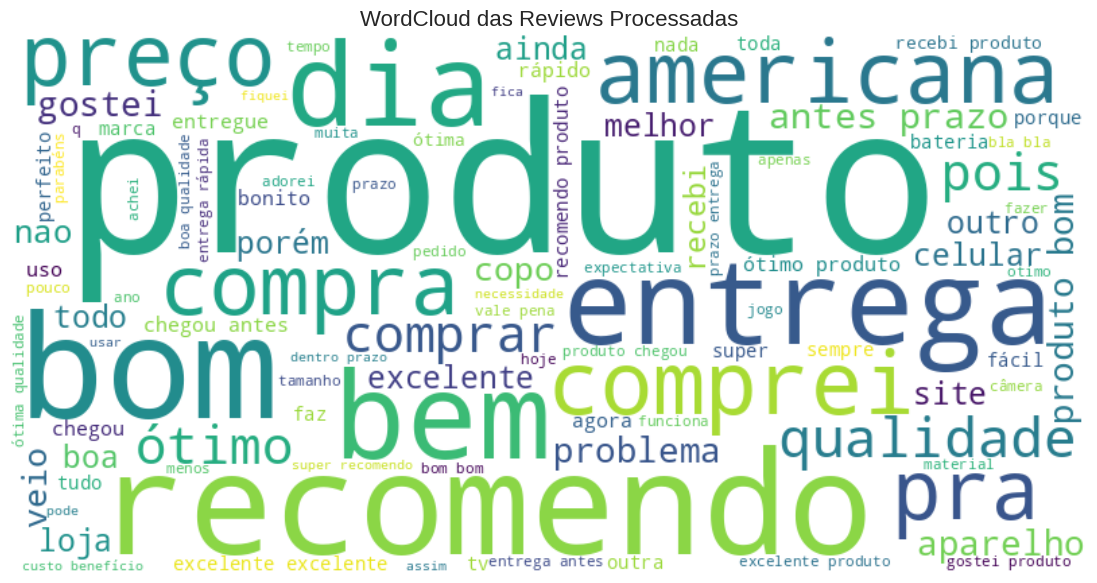

In [ ]:
# Gerar WordCloud com os tokens processados
todos_tokens_viz = []
for tokens in df_processado['tokens_processados']:
    todos_tokens_viz.extend(tokens)

texto_wordcloud = ' '.join(todos_tokens_viz)

wc = WordCloud(
    width=800, height=400,
    background_color='white',
    max_words=100,
    colormap='viridis'
).generate(texto_wordcloud)

plt.figure(figsize=(14, 7))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title('WordCloud das Reviews Processadas', fontsize=16)
plt.show()

---

**Certifique-se de que todos os testes passaram antes de submeter.**